In [1]:
import torch
print(torch.__version__, torch.cuda.is_available())

2.11.0+cu128 True


In [2]:
import json
from pathlib import Path

import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# Change this if you moved the data
DATA_DIR = Path.home() / "brain-tumor-seg" / "data"

CHANNELS = ["FLAIR", "T1w", "T1gd", "T2w"]
LABEL_NAMES = {0: "background", 1: "edema",
               2: "non-enhancing tumor", 3: "enhancing tumor"}

In [3]:
with open(DATA_DIR / "dataset.json") as f:
    meta = json.load(f)

cases = []
for item in meta["training"]:
    img_path = DATA_DIR / item["image"].removeprefix("./")
    lbl_path = DATA_DIR / item["label"].removeprefix("./")
    cases.append((img_path, lbl_path))

print(len(cases))
assert all(i.exists() and l.exists() for i, l in cases)
print(cases[0])


484
(PosixPath('/home/asteris/brain-tumor-seg/data/imagesTr/BRATS_457.nii.gz'), PosixPath('/home/asteris/brain-tumor-seg/data/labelsTr/BRATS_457.nii.gz'))


In [4]:
def load_case(img_path, lbl_path):
    """Return image (C, H, W, D) float32, label (H, W, D) uint8, and metadata."""

    img_nii = nib.load(img_path)
    lbl_nii = nib.load(lbl_path)

    data = np.asarray(img_nii.dataobj, dtype = np.float32)      # expected (H, W, D, 4)
    assert data.shape[-1] == 4, f"unexpected shape {data.shape}"
    data = np.moveaxis(data, -1, 0)

    lbl = np.asarray(lbl_nii.dataobj).astype(np.uint8) 

    info = {
        "spacing": img_nii.header.get_zooms()[:3],
        "axcodes": nib.aff2axcodes(img_nii.affine),
        "dtype_on_disk": img_nii.get_data_dtype(),
    }

    return data, lbl, info



In [5]:
img, lbl, info = load_case(*cases[40])

print("image:", img.shape, img.dtype)
print("label:", lbl.shape, lbl.dtype)
print("spacing (mm):", info["spacing"])
print("orientation:", info["axcodes"])
print("dtype on disk:", info["dtype_on_disk"])

print("\nPer channel:")
for name, ch in zip(CHANNELS, img):
    nz = ch[ch != 0]
    print(f"{name:5s} min={ch.min():8.1f} max={ch.max():8.1f} "
          f"mean(nonzero)={nz.mean():8.1f} zero_frac={(ch == 0).mean():.2f}")

print("\nLabels:")
vals, counts = np.unique(lbl, return_counts=True)
for v, c in zip(vals, counts):
    print(f"{v} {LABEL_NAMES[v]:20s} {c:8d} voxels  {100 * c / lbl.size:6.3f}%")

image: (4, 240, 240, 155) float32
label: (240, 240, 155) uint8
spacing (mm): (np.float32(1.0), np.float32(1.0), np.float32(1.0))
orientation: ('R', 'A', 'S')
dtype on disk: float32

Per channel:
FLAIR min=     0.0 max=  1822.0 mean(nonzero)=   517.1 zero_frac=0.82
T1w   min=     0.0 max=  2007.0 mean(nonzero)=   779.4 zero_frac=0.82
T1gd  min=     0.0 max=  2458.0 mean(nonzero)=   802.3 zero_frac=0.82
T2w   min=     0.0 max=  1453.0 mean(nonzero)=   528.7 zero_frac=0.82

Labels:
0 background            8784204 voxels  98.389%
1 edema                  124893 voxels   1.399%
2 non-enhancing tumor     15845 voxels   0.177%
3 enhancing tumor          3058 voxels   0.034%


slice: 93 | tumor voxels in it: 3596


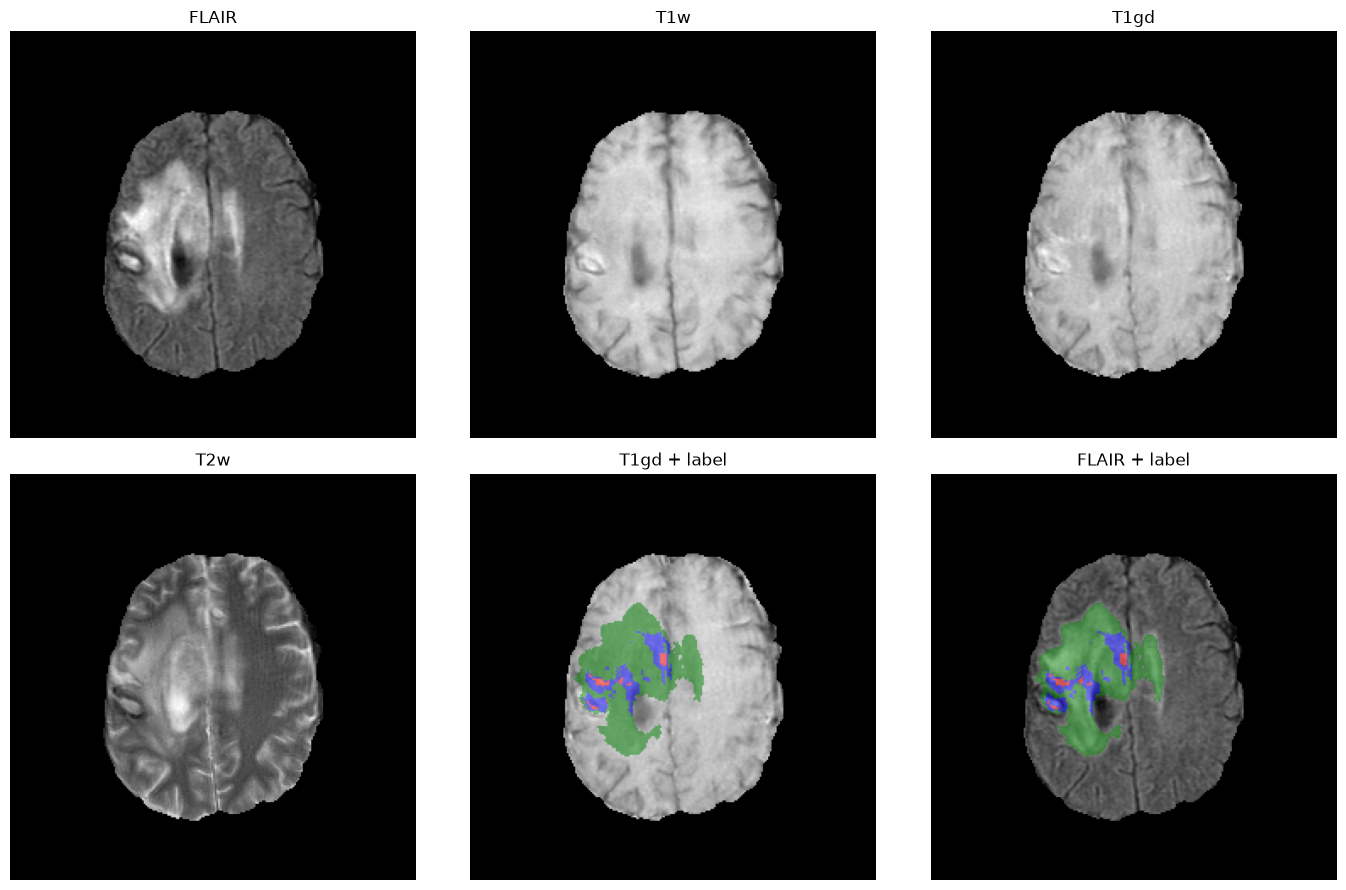

In [6]:
tumor_per_slice = (lbl>0).sum(axis = (0,1))
k = int(tumor_per_slice.argmax())
print("slice:", k, "| tumor voxels in it:", tumor_per_slice[k])

def show(slice2d):
    return slice2d.T

overlay_cmap = ListedColormap(["none", "green", "blue", "red"])
lbl_slice = show(lbl[:,:,k])
lbl_masked = np.ma.masked_where(lbl_slice == 0, lbl_slice)


fig, axes = plt.subplots(2, 3, figsize=(14, 9))
axes = axes.ravel()

for i, name in enumerate(CHANNELS):
    axes[i].imshow(show(img[i, :, :, k]), cmap="gray", origin="lower")
    axes[i].set_title(name)

for ax, c, title in [(axes[4], 2, "T1gd + label"), (axes[5], 0, "FLAIR + label")]:
    ax.imshow(show(img[c, :, :, k]), cmap="gray", origin="lower")
    ax.imshow(lbl_masked, cmap=overlay_cmap, vmin=0, vmax=3,
              alpha=0.5, origin="lower")
    ax.set_title(title)

for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()



In [7]:
import pandas as pd
from tqdm.auto import tqdm

rng = np.random.default_rng(42)
sample_idx = rng.choice(len(cases), size = len(cases), replace=False)

rows = []

for i in tqdm(sample_idx):
    img, lbl, info = load_case(*cases[i])
    brain = img[0] != 0

    row = {
        "case": cases[i][0].name,
        "shape": img.shape[1:],
        "spacing": tuple(round(float(s), 3) for s in info["spacing"]),
        "axcodes": "".join(info["axcodes"]),
        "brain_frac": brain.mean(),

    }


    for name, ch in zip(CHANNELS, img):
        vals = ch[brain]
        row[f"{name}_mean"] = vals.mean()
        row[f"{name}_std"] = vals.std()
        row[f"{name}_p99"] = np.percentile(vals, 99)


    counts = np.bincount(lbl.ravel(), minlength=4)
    for v in range(4):
        row[f"n_label{v}"] = counts[v]
    row[f"tumor_vox"] = counts[1:]. sum()

    rows.append(row)

df = pd.DataFrame(rows)
df.head()

print(len(df))                                   # expect 484
print(df["case"].nunique())                      # expect 484, no duplicates

STATS_PATH = Path.home() / "brain-tumor-seg" / "data" / "stats.csv"
df.to_csv(STATS_PATH, index=False)
print("saved to", STATS_PATH)


    

  0%|          | 0/484 [00:00<?, ?it/s]

484
484
saved to /home/asteris/brain-tumor-seg/data/stats.csv


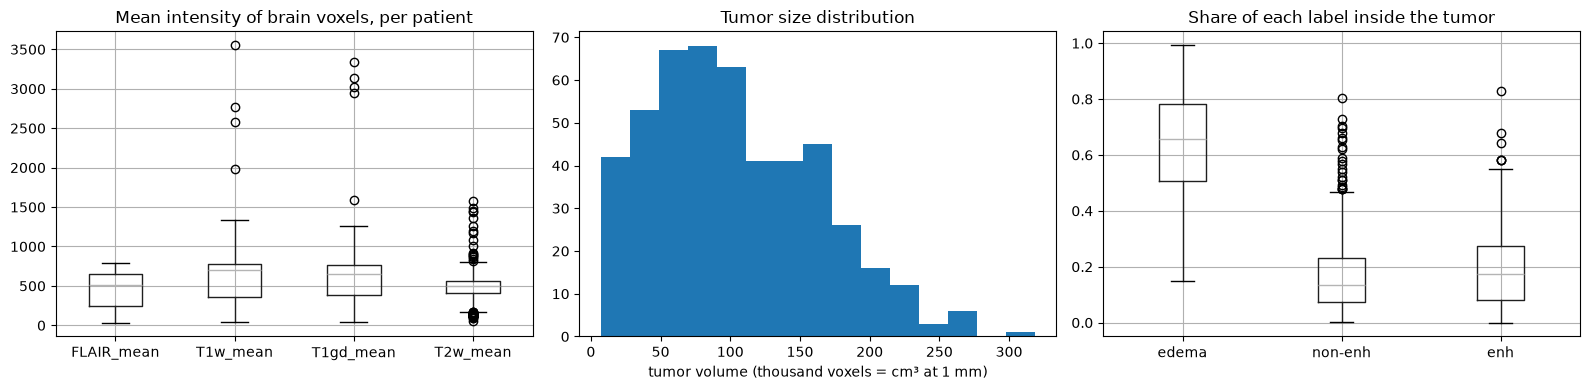

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# (a) intensity means per channel across patients
df[[f"{c}_mean" for c in CHANNELS]].boxplot(ax=axes[0])
axes[0].set_title("Mean intensity of brain voxels, per patient")

# (b) tumor volume distribution
axes[1].hist(df["tumor_vox"] / 1000, bins=15)
axes[1].set_xlabel("tumor volume (thousand voxels = cm³ at 1 mm)")
axes[1].set_title("Tumor size distribution")

# (c) label composition inside the tumor
comp = df[["n_label1", "n_label2", "n_label3"]].div(df["tumor_vox"], axis=0)
comp.columns = ["edema", "non-enh", "enh"]
comp.boxplot(ax=axes[2])
axes[2].set_title("Share of each label inside the tumor")

plt.tight_layout()
plt.show()

In [9]:
print("shapes:", df["shape"].value_counts().to_dict())
print("spacing:", df["spacing"].value_counts().to_dict())
print("axcodes:", df["axcodes"].value_counts().to_dict())
print()
print(df[["brain_frac", "tumor_vox"]].describe())
print()
print(df[[f"{c}_mean" for c in CHANNELS]].describe())    # spread of means = why we normalize

shapes: {(240, 240, 155): 484}
spacing: {(1.0, 1.0, 1.0): 484}
axcodes: {'RAS': 484}

       brain_frac      tumor_vox
count  484.000000     484.000000
mean     0.160607  103299.617769
std      0.014892   59269.356479
min      0.090196    7285.000000
25%      0.151483   57435.750000
50%      0.160879   94221.500000
75%      0.170653  147549.250000
max      0.208045  318345.000000

       FLAIR_mean     T1w_mean    T1gd_mean     T2w_mean
count  484.000000   484.000000   484.000000   484.000000
mean   460.912964   606.381348   604.025513   481.614624
std    216.167160   300.402466   317.439026   202.211807
min     34.451878    39.370003    44.579395    59.315243
25%    239.066345   354.639534   389.658241   408.999802
50%    516.177582   695.810059   650.236237   501.878311
75%    653.540146   774.034698   761.324463   568.586090
max    795.309631  3552.305176  3343.962402  1576.755859


In [10]:
for col in ["shape", "spacing", "axcodes"]:
    print(col, df[col].astype(str).value_counts().to_dict())

cols = ["case"] + [f"{c}_mean" for c in CHANNELS]
print(df.sort_values("T1w_mean", ascending=False)[cols].head(10 ))

print((df[["n_label1", "n_label2", "n_label3"]] == 0).sum())
print(df["tumor_vox"].describe())

shape {'(240, 240, 155)': 484}
spacing {'(1.0, 1.0, 1.0)': 484}
axcodes {'RAS': 484}
                 case  FLAIR_mean     T1w_mean    T1gd_mean     T2w_mean
448  BRATS_453.nii.gz  795.309631  3552.305176  1589.801758  1367.053955
109  BRATS_416.nii.gz  705.242676  2767.113770  3025.202637  1446.278564
395  BRATS_479.nii.gz  508.932312  2575.363770  3343.962402  1254.460815
244  BRATS_460.nii.gz  391.285950  1981.264648   922.755249   887.751587
328  BRATS_385.nii.gz  760.459290  1341.354980   832.128235   877.341919
116  BRATS_403.nii.gz  697.223755  1154.469604  2951.706543  1434.606934
98   BRATS_389.nii.gz  542.691650  1141.562866   962.647522  1490.478760
438  BRATS_405.nii.gz  528.897095  1131.128662  3133.462158  1008.586121
258  BRATS_454.nii.gz  615.379333  1032.035156  1254.049072  1576.755859
271  BRATS_394.nii.gz  434.363464   965.658936  1026.533569   520.389099
n_label1     0
n_label2     0
n_label3    12
dtype: int64
count       484.000000
mean     103299.617769
std     

In [14]:
### MAKE THE DATASET SPLIT
from sklearn.model_selection import train_test_split


df["size_bin"] = pd.qcut(df["tumor_vox"], q=3, labels=False)
df["has_enh"] = (df["n_label3"]>0).astype(int)
df["strata"] = df["size_bin"].astype(str) + "_" + df["has_enh"].astype(int).astype(str)

print(df["strata"].value_counts().sort_index())


SEED = 42

trainval, test = train_test_split(
    df, test_size=0.15, stratify=df["strata"], random_state=SEED
)

train, val = train_test_split(
    trainval, test_size=0.15/0.85, stratify=trainval["strata"], random_state=SEED
)

split = {
  "train" : sorted(train["case"].tolist()),
  "val" : sorted(val["case"].tolist()),
  "test" : sorted(test["case"].tolist())
}

assert not set(split["train"]) & set(split["val"])
assert not set(split["train"]) & set(split["test"])
assert not set(split["val"])   & set(split["test"])
assert sum(len(v) for v in split.values()) == 484

CONFIG_DIR = Path.home() / "brain-tumor-seg" / "configs"
with open(CONFIG_DIR/ "split_seed42.json", "w") as f:
    json.dump(split, f, indent= 2)

strata
0_0     12
0_1    150
1_1    161
2_1    161
Name: count, dtype: int64
